# Indonesian Through Flow (ITF) transport

Volume transport based on gradients in Sea Surface Height (SSH) between Pacific and Indian ocean in ACCESS-OM2, ACCESS-OM3 and observations

Susanto and Song, 2015 --> proxy ITF transport through Makassar Strait --> gradients in SSH and OBP
(https://doi.org/10.1002/2014JC010382)

Optimal locations for calculating gradients/ differences in SSH/ OBP
- Pacific: 162$^\circ E$, 11$^\circ N$
- Indian: 80$^\circ E$, 0$^\circ N$

Shilimkar et al. 2022 (http://doi.org/10.1007/s10872-022-00641-w) --> proxy ITF based on and Wyrtki’s (1987) --> gradients in SSH anomalies

Shilimkar uses instead of optimal locations averages of spatial regions in the Pacific and Indian Ocean

## Setting up

Related issue: https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/5

https://access-nri.zulipchat.com/#narrow/channel/470332-ocean-seaice/topic/Evaluation/near/512462625

 - SSH - SEALEVEL_GLO_PHY_L4_MY_008_047 is in kj13 /g/data/kj13/datasets/cosima/CMEMS and have started a CMORiser in ESMValTool working for monthly
 - AVISO Altimetry Antarctic -kj13 : /g/data/kj13/datasets/cosima/AVISO-Altimetry

Both the above are also in:
 - /g/data/av17/access-nri-temporary/OM3/CMEMS
 - /g/data/av17/access-nri-temporary/OM3/AVISO-Altimetry

Hacked from:
 - https://cosima-recipes.readthedocs.io/en/latest/02-Appetisers/Compare_SSH_model_obs.html (nb: `ua8` is no longer accepting new members)
 - https://github.com/ACCESS-Community-Hub/access-om3-paper-1/blob/main/notebooks/SST.ipynb

Related chat:
 - https://access-nri.zulipchat.com/#narrow/channel/470332-ocean-seaice/topic/Evaluation/near/544659613
 - https://github.com/COSIMA/cosima-recipes/issues/549

NB: with 25km monthly output runs okay on an ARE "large" job.

**If using the daily sattelite obs one needs to use `normalsr` queue with 104 cores/496 Gb**

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file = '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/datastore.json'
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
# esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from model_agnostic import patch_broken_conda_env
patch_broken_conda_env()  # conda env workaround for analysis3-26.03+; no-op on healthy envs

In [3]:
import xarray as xr
import cf_xarray as cfxr
import cf_xarray.units
import pint_xarray
from pint import application_registry as ureg
import intake
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from distributed import Client
import cftime
import os
import matplotlib.pyplot as plt
import cmocean as cm
import cartopy.crs as ccrs
import cartopy.feature as cft
from textwrap import wrap
xr.set_options(keep_attrs=True);  # cf_xarray works best when xarray keeps attributes by default
import glob

In [4]:
import pandas as pd

In [5]:
client = Client(threads_per_worker=1)
from model_agnostic import patch_dask_workers
patch_dask_workers(client)  # patch workers too
client

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 46829 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/46829/status,
Dashboard: /proxy/46829/status,Workers: 28
Total threads: 28,Total memory: 126.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:44479,Workers: 0
Dashboard: /proxy/46829/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:38901,Total threads: 1
Dashboard: /proxy/34585/status,Memory: 4.50 GiB
Nanny: tcp://127.0.0.1:37679,


In [6]:
#here we set the years that we are interested in
start_time = '1993-01-01'
end_time = '2023-12-31'

start_year=int(start_time.split('-')[0])
end_year=int(end_time.split('-')[0])


In [7]:
# set time range
datestart= cftime.DatetimeProlepticGregorian(start_year, 1,  16, 12, 0, 0, 0, has_year_zero=True)  # to match OM2 IAF run
datestop = cftime.DatetimeProlepticGregorian(end_year, 12, 16, 12, 0, 0, 0, has_year_zero=True)  # to match OM2 IAF run
timerange = slice(datestart, datestop)

datestart,datestop

(cftime.DatetimeProlepticGregorian(1993, 1, 16, 12, 0, 0, 0, has_year_zero=True),
 cftime.DatetimeProlepticGregorian(2023, 12, 16, 12, 0, 0, 0, has_year_zero=True))

## Select regional data

In [8]:
# region we are interested in
north_latitude, south_latitude = 20, -20
west_longitude, east_longitude = 60, 170
central_longitude, central_latitude = 120, 5

lon_sel, lat_sel = slice(west_longitude, east_longitude), slice(south_latitude, north_latitude)

In [9]:
# susanto and song, 2025 optimal locations
lon_indian, lat_indian = 80, 0
lon_pacific, lat_pacific = 162, 11

# Shilimkar et al. 2021 regions
coord_names = {
    'om2': {'X' :'xt_ocean', 'Y' :'yt_ocean'},
    'om3': {'X' :'xh', 'Y' :'yh'},
    'obs': {'X' :'longitude', 'Y' :'latitude'},
}
regions = {
    'NWP':  {'lon': slice(125, 155), 'lat': slice(6, 16)},
    'SEI':  {'lon': slice(85, 115),  'lat': slice(-16, -6)},
    'EEIO': {'lon': slice(65, 95),   'lat': slice(-5, 5)},
    'ITF': {'lon': slice(west_longitude, east_longitude), 'lat': slice(south_latitude, north_latitude)}
}

# ITF transport section (Shilimkar et al. 2022, Fig. 1): along 115E from Australia to Indonesia
itf_lon = 115               # degrees E
itf_lat = slice(-20, -9)    # Shilimkar et al. (2022); coast-to-coast in OM3: slice(-21.7, -8.5)

def select_region(ds, ds_key, region_key):
    xname, yname = coord_names[ds_key]['X'], coord_names[ds_key]['Y']
    reg = regions[region_key]

    # normalize this dataset's longitude coord to 0-360 and sort
    if ds_key in ['om2', 'om3']:
        ds = ds.assign_coords({xname: ds[xname] % 360}).sortby(xname)

    sel_dict = {xname: reg['lon'], yname: reg['lat']}
    return ds.sel(sel_dict)

## SSH from 0.25$^{\circ}$ ACCESS-OM2 model output

In [10]:
# SSH variable in ACCESS-OM2 models
variable = 'sea_level'

catalog = intake.cat.access_nri
var_search = catalog['025deg_jra55_iaf_omip2_cycle6'].search(variable=variable, frequency='1mon')
ssh_om2 = var_search.to_dask()
# ssh_om2 = ssh_om2.assign_coords({"xt_ocean": ssh_om2.xt_ocean % 360})
# ssh_om2 = ssh_om2.sortby("xt_ocean")


You can see we have a very large number of chunks, so lets rechunk.

In [11]:
ssh_om2_tm = ssh_om2.sel(time=slice(start_time, end_time))
tstart_om2, tend_om2 = pd.to_datetime(ssh_om2_tm.time.values[0]), pd.to_datetime(ssh_om2_tm.time.values[-1])

In [12]:
#this cell will take a bit (few minutes)
# 0.25 deg:
# ssh025_mean = ssh025.mean(dim='time').load()
# ssh025_std  = ssh025.std(dim='time', skipna=False).load()

In [13]:
var_search = catalog['025deg_jra55_iaf_omip2_cycle6'].search(variable="area_t")
ds = var_search.search(path=var_search.df["path"][0]).to_dask()
geolon_t = ds.geolon_t.sel(yt_ocean=lat_sel, xt_ocean=lon_sel)
geolat_t = ds.geolat_t.sel(yt_ocean=lat_sel, xt_ocean=lon_sel)

ssh_om2_tm = ssh_om2_tm.assign_coords({"geolon_t": geolon_t, "geolat_t": geolon_t})
# # ssh025_std = ssh025_std.assign_coords({"geolon_t": geolon_t_025, "geolat_t": geolat_t_025})

## SSH from 0.25$^{\circ}$ ACCESS-OM3 model output

In [14]:
# os.listdir(os.path.join(os.sep, 'g', 'data', 'ol01', 'outputs', 'access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88'))

In [15]:
from exptdata_access import get_exptname_from_path
exptname = get_exptname_from_path(esm_file)
print(exptname)
datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=[
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
    ]
)

MC_25km_jra_iaf+wombatlite-test5.1-8f50b769


In [16]:
from model_agnostic import get_lon_lat_from_catalog
geolon, geolat = get_lon_lat_from_catalog(datastore)

In [17]:
variable = "zos"
ssh_om3 = datastore.search(variable=variable).to_dask(
    xarray_open_kwargs = dict(
        chunks={"time": -1},
        decode_timedelta=True
    ),
    xarray_combine_by_coords_kwargs=dict(
        compat="override",
        data_vars="minimal",
        coords="minimal"
    )
)[variable]#.cf.assign_coords({ "longitude": geolon, "latitude": geolat })

In [18]:
# geolon_sel = geolon.sel(yh=lat_sel, xh=lon_sel)
# geolat_sel = geolat.sel(yh=lat_sel, xh=lon_sel)
# ssh_om3_itf = ssh_om3.sel(yh=lat_sel, xh=lon_sel)#.cf.assign_coords({ "longitude": geolon_sel, "latitude": geolat_sel })


In [19]:
# zos_om3 = zos_om3.assign_coords({"yh": zos_om3.yh.sortby("yh")})

In [20]:
# %%time
# this should really use the square field (although it makes the om2 comparison apples-to-oranges)
# zos_om3_itf_std = zos_om3_itf.sel(time=timerange).std('time').load()

In [21]:
# for IAF
ssh_om3 = ssh_om3.convert_calendar("proleptic_gregorian", use_cftime=True)

# initial and final date in data
ssh_om3_tm = ssh_om3.sel(time=timerange)
tstart_om3, tend_om3 = ssh_om3_tm.time.values[0], ssh_om3_tm.time.values[-1]

## Read in observations

source: /g/data/av17/access-nri-temporary/OM3/CMEMS/

name: SEALEVEL_GLO_PHY_L4_MY_008_047C
experiment_uuid: dbce7aa9-f0d6-4d5d-98eb-3d995add2f12
description: Global Ocean Gridded L4 Sea Surface Heights And Derived Variables Reprocessed 1993 Ongoing
long_description: >-
  Altimeter satellite gridded Sea Level Anomalies (SLA) computed with respect to a twenty-year [1993, 2012] mean. The SLA is estimated by Optimal Interpolation, merging the L3 along-track measurement from the different altimeter missions available. Part of the processing is fitted to the Global ocean. (see QUID document or http://duacs.cls.fr pages for processing details). The product gives additional variables (i.e. Absolute Dynamic Topography and geostrophic currents (absolute and anomalies)). It serves in delayed-time applications. This product is processed by the DUACS multimission altimeter data processing system.

version: 
contact: Copernicus Marine Service
email: https://data.marine.copernicus.eu/product/SEALEVEL_GLO_PHY_L4_MY_008_047/contacts
created: 
reference: https://doi.org/10.48670/moi-00148
license: https://marine.copernicus.eu/user-corner/service-commitments-and-licence
url: https://data.marine.copernicus.eu/product/SEALEVEL_GLO_PHY_L4_MY_008_047/description

In [22]:
import numpy as np
filenames=[]

#for debugging if you want a tiny dataset
# for year in np.arange(start_year,1994+1):
#     filenames.append(sorted(glob.glob("/g/data/av17/access-nri-temporary/OM3/CMEMS/SEALEVEL_GLO_PHY_L4_MY_008_047/cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1D_202411/"+str(year)+"/11/*1101_*15*.nc")))

freq = 'monthly'

if freq == 'daily':
    #for daily data
    for year in np.arange(start_year,end_year+1):
        #print(year)
        filenames.append(sorted(glob.glob("/g/data/av17/access-nri/OM3/CMEMS/SEALEVEL_GLO_PHY_L4_MY_008_047/cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1D_202411/"+str(year)+"/*/*.nc")))
if freq == 'monthly':
    # for monthly data
    for year in np.arange(start_year,end_year+1):
        #print(year)
        filenames.append(sorted(glob.glob("/g/data/av17/access-nri/OM3/CMEMS/SEALEVEL_GLO_PHY_L4_MY_008_047/cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1M-m_202411/"+str(year)+"/*.nc")))

#make list of lists into just a list
filenames = [item for sublist in filenames for item in sublist]

In [23]:
%%time
#this was taking ages on daily data, so Dougie suggested adding: data_vars='minimal', coords='minimal', compat='override' -- should avoid any issues with messy metadata -- see docs: https://docs.xarray.dev/en/stable/generated/xarray.open_mfdataset.html
# cmems = xr.open_mfdataset(
#     filenames, parallel=True,concat_dim="time", combine="nested", data_vars='minimal', coords='minimal', compat='override',chunks="auto")
# ssh_obs = cmems.adt
# ssha_obs = cmems.sla
preprocess=lambda ds: ds['adt']
if freq == 'monthly':
    preprocess=lambda ds: ds['sla']
ssh_obs = xr.open_mfdataset(filenames, preprocess=preprocess, parallel=True, chunks="auto") #,concat_dim="time", combine="nested", data_vars='minimal', coords='minimal', compat='override'

#faster with 28 cores compared to 14 (~1.5 minutes)

CPU times: user 15 s, sys: 12 s, total: 27 s
Wall time: 34.1 s


In [24]:
# Absolute dynamic topography: adt = sla + mdt, with mdt the (time-invariant) mean dynamic topography.
# The monthly files only contain `sla`, so take mdt = adt - sla from a single daily file (same 1/8 deg grid)
# and add it to the monthly sla. Use `adt` for mean-state maps and absolute SSH differences;
# for anomalies sla and adt are equivalent (mdt cancels).
if freq == 'monthly':
    daily_file = sorted(glob.glob("/g/data/av17/access-nri/OM3/CMEMS/SEALEVEL_GLO_PHY_L4_MY_008_047/cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1D_202411/"+str(start_year)+"/01/*.nc"))[0]
    with xr.open_dataset(daily_file) as d:
        mdt = (d.adt - d.sla).squeeze(drop=True).load()
    mdt, _ = xr.align(mdt, ssh_obs, join="exact")  # fail loudly if the daily and monthly grids ever differ
    ssh_obs["adt"] = ssh_obs["sla"] + mdt
    ssh_obs["adt"].attrs.update(long_name="Absolute dynamic topography (monthly sla + mdt)", units="m")

var = 'adt'  # observed SSH variable used below
ssh_obs

<xarray.Dataset> Size: 25GB
Dimensions:    (time: 372, latitude: 1440, longitude: 2880)
Coordinates:
  * time       (time) datetime64[ns] 3kB 1993-01-15 1993-02-15 ... 2023-12-15
  * latitude   (latitude) float32 6kB -89.94 -89.81 -89.69 ... 89.69 89.81 89.94
  * longitude  (longitude) float32 12kB -179.9 -179.8 -179.7 ... 179.8 179.9
Data variables:
    sla        (time, latitude, longitude) float64 12GB dask.array<chunksize=(1, 1440, 2880), meta=np.ndarray>
    adt        (time, latitude, longitude) float64 12GB dask.array<chunksize=(1, 1440, 2880), meta=np.ndarray>

In [25]:
# for daily files
# The absolute dynamic topography is the sea surface height above geoid; the adt is obtained as follows: adt=sla+mdt where mdt is the mean dynamic topography; see the product user manual for details
# ssh_obs = cmems.adt

# lon_sel = slice(west_longitude, east_longitude)
# ssh_obs_itf = ssh_obs.sel(latitude=lat_sel, longitude=lon_sel)

# tstart_obs, tend_obs = pd.to_datetime(ssh_obs_itf.time.values[0]), pd.to_datetime(ssh_obs_itf.time.values[-1])

# obs_ssh = obs_ssh.rename('adt_cmems')

# for daily files
# obs_ssh = cmems.sla 
# obs_ssh = obs_ssh.rename('adt_cmems')


In [26]:
#from Anton -- could use this kind of command to reduce the obs down to the model frequency but I think it makes more sense to use ssh^2 fields from model.
#obs_ssh_mean= obs_ssh.groupbyt('time.month').mean('time').std(dim='time', skipna=False)
#obs_ssh_std = obs_ssh.groupbyt('time.month').mean('time').std(dim='time', skipna=False)

#AS: sorry - this should be a resample not a groupby !
#AS: groupby would give a climatology (a monthly mean of all years). resample would give a mean for every month (e.g like change from daily to monthly data)

In [27]:
if freq == 'daily':
    ssh_obs_resample = ssh_obs[['adt']].resample(time='1MS').mean()

tstart_obs, tend_obs = pd.to_datetime(ssh_obs.time.values[0]), pd.to_datetime(ssh_obs.time.values[-1])

## Gradients in SSH between Pacific and Indian (point-based)

In [28]:
if freq == 'daily':
    deta_obs = (ssh_obs_resample.sel(latitude=lat_pacific, longitude=lon_pacific, method='nearest') 
                - ssh_obs_resample.sel(latitude=lat_indian, longitude=lon_indian, method='nearest')).load()
else:
    deta_obs = (ssh_obs.sel(latitude=lat_pacific, longitude=lon_pacific, method='nearest') 
                - ssh_obs.sel(latitude=lat_indian, longitude=lon_indian, method='nearest')).load()
    
deta_om3 = (ssh_om3.sel(yh=lat_pacific, xh=lon_pacific, method='nearest') 
- ssh_om3.sel(yh=lat_indian, xh=lon_indian, method='nearest')).load()
deta_om2 = (ssh_om2.sel(yt_ocean=lat_pacific, xt_ocean=lon_pacific, method='nearest') 
- ssh_om2.sel(yt_ocean=lat_indian, xt_ocean=lon_indian, method='nearest')).load()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 32.46 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


## Mean SSH in the ITF region
Select regional data and time mean

In [29]:
%%time
# ITF-region subsets for the mean-state maps (NWP/SEI box means are computed, area-weighted, in the SSH anomaly section below)
ssh_obs_itf = select_region(ssh_obs, 'obs', 'ITF')
ssh_om3_itf = select_region(ssh_om3_tm, 'om3', 'ITF')
ssh_om2_itf = select_region(ssh_om2_tm, 'om2', 'ITF')


CPU times: user 185 ms, sys: 130 ms, total: 315 ms
Wall time: 225 ms


In [30]:
%%time
#on daily data this cell didn't run properly with 28 cores/252 gb. Needed `normalsr` queue with 104 cores/496 Gb
ssh_obs_itf_tm = ssh_obs_itf.mean(dim='time').load()
# obs_ssh_std  = obs_ssh.std(dim='time', skipna=False).load()

ssh_om3_itf_tm = ssh_om3_itf.mean('time').load()
ssh_om2_itf_tm = ssh_om2_itf.mean('time').load()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 32.42 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


CPU times: user 7.96 s, sys: 4.1 s, total: 12.1 s
Wall time: 12 s


## Plot ACCESS-OM2, ACCESS-OM3 and obs


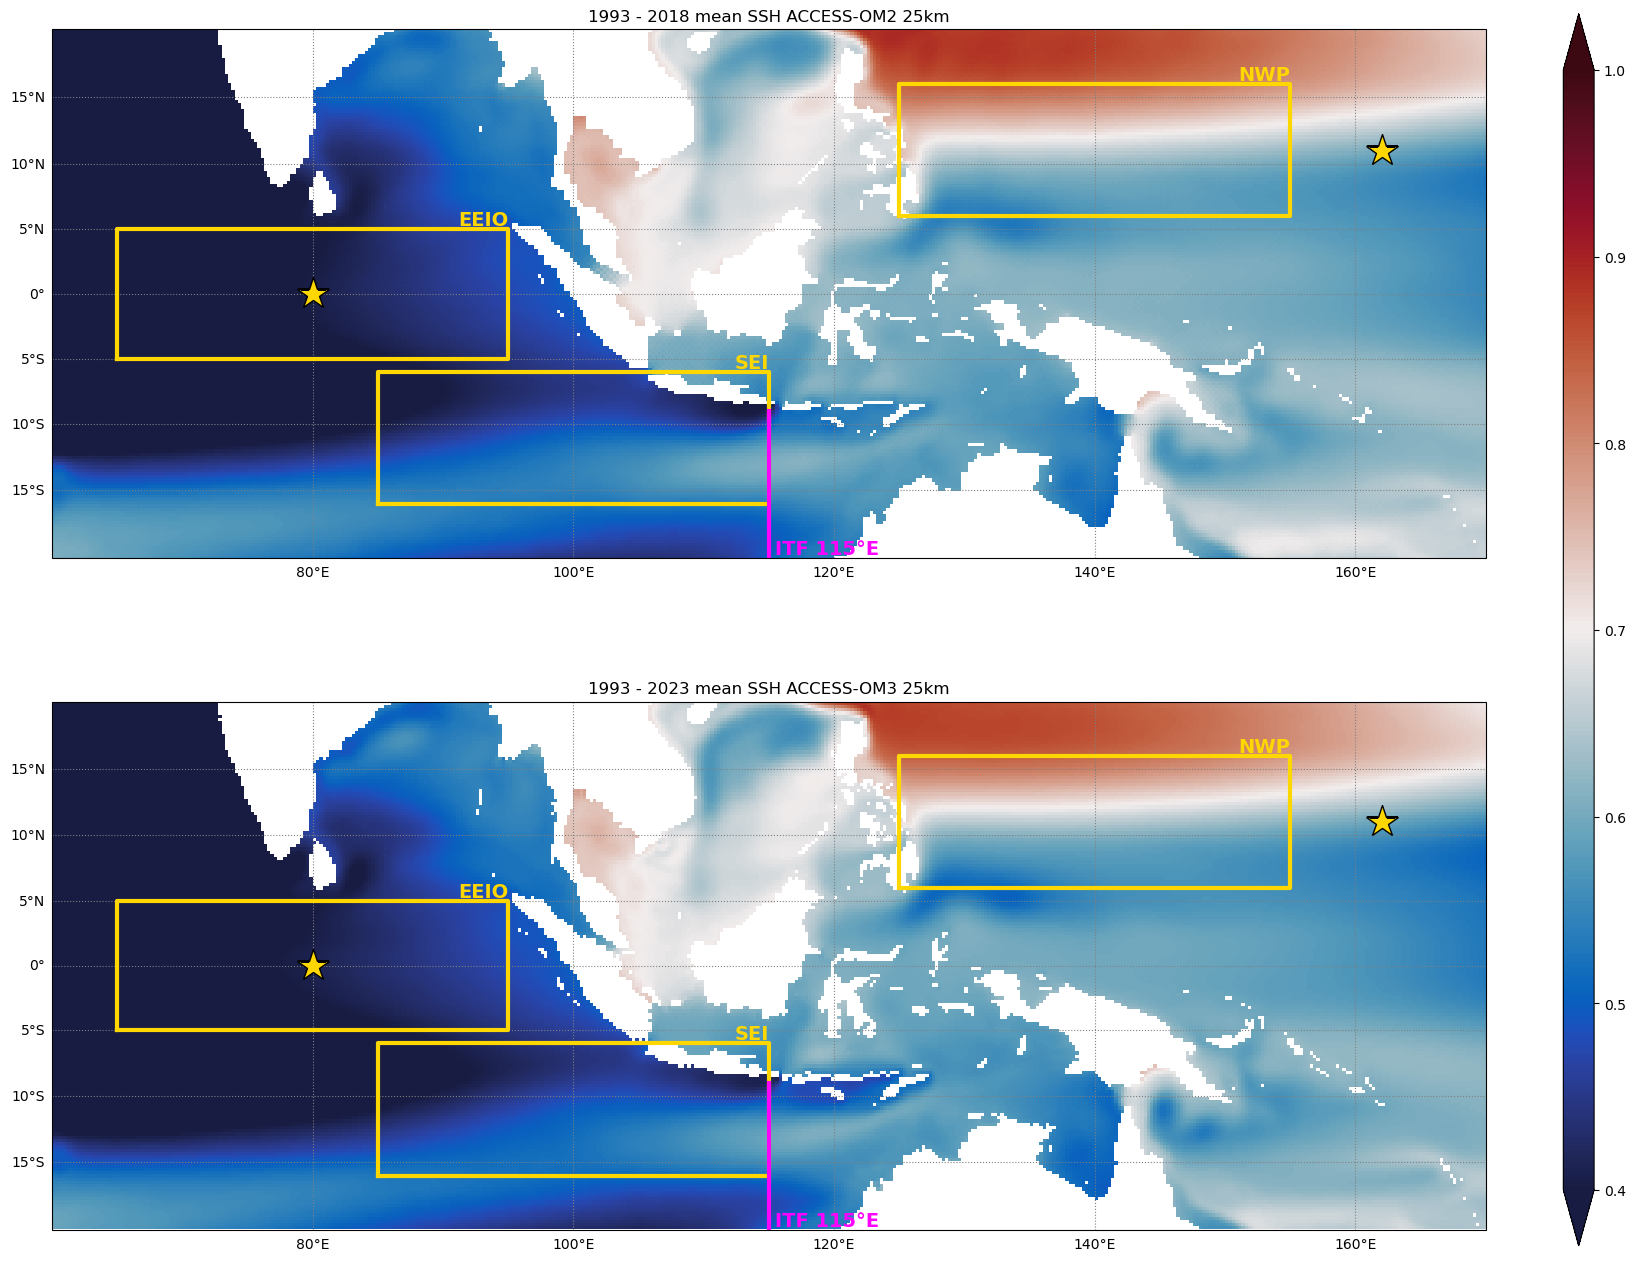

In [31]:
projection = ccrs.Mercator(central_longitude=central_longitude, min_latitude=south_latitude, max_latitude=north_latitude)

vmin, vmax = 0.4, 1

fig, axes = plt.subplots(nrows = 2, figsize = (20, 16), subplot_kw={'projection': projection}) #nrows = 3, ncols = 2, 
plt.subplots_adjust(wspace=-0.15)

p0 = ssh_om2_itf_tm.sea_level.plot(
    ax = axes[0],
    vmin=vmin, vmax=vmax,
    add_colorbar=False,
    cmap = cm.cm.balance,
    transform = ccrs.PlateCarree())
axes[0].set_title(f"{tstart_om2.strftime('%Y')} - {tend_om2.strftime('%Y')} "'mean SSH ACCESS-OM2 25km')


# ax = axes[1, 0]
p1 = ssh_om3_itf_tm.plot(
    ax = axes[1],
    vmin=vmin, vmax=vmax,
    add_colorbar=False,
    cmap = cm.cm.balance,
    transform = ccrs.PlateCarree())
axes[1].set_title(f"{tstart_om3.strftime('%Y')} - {tend_om3.strftime('%Y')} "+'mean SSH ACCESS-OM3 25km')

for iax in range(axes.size):
#     # r, c = iax // ncols, iax % ncols
    axes[iax].plot(lon_indian, lat_indian, '*', markersize=20, color='yellow', transform = ccrs.PlateCarree())
    axes[iax].plot(lon_pacific, lat_pacific, '*', markersize=20, color='yellow', transform = ccrs.PlateCarree())
#     # ax[r, c].add_feature(land, zorder=5)
    gl = axes[iax].gridlines(color='grey', linestyle=':', draw_labels=True) #ylocs=[-45, -60, -75])
    gl.top_labels = False
    gl.right_labels = False

    axes[iax].plot(lon_indian, lat_indian, '*', markersize=24, color='gold', markeredgecolor='k', transform = ccrs.PlateCarree())
    axes[iax].plot(lon_pacific, lat_pacific, '*', markersize=24, color='gold', markeredgecolor='k', transform = ccrs.PlateCarree())
    for region in regions:
        if region != 'ITF':
            lon_w, lon_e = regions[region]['lon'].start, regions[region]['lon'].stop
            lat_s, lat_n = regions[region]['lat'].start, regions[region]['lat'].stop
            axes[iax].plot([lon_w, lon_e, lon_e, lon_w, lon_w], [lat_s, lat_s, lat_n, lat_n, lat_s], color='gold', linewidth=3, transform=ccrs.PlateCarree())
            axes[iax].text(lon_e, lat_n, region, color='gold', fontsize=14, fontweight='bold', va='bottom', ha='right', transform=ccrs.PlateCarree())
    # ITF transport section (115E)
    axes[iax].plot([itf_lon, itf_lon], [itf_lat.start, itf_lat.stop], color='magenta', linewidth=3, transform=ccrs.PlateCarree())
    axes[iax].text(itf_lon + 0.5, itf_lat.start, f'ITF {itf_lon}°E', color='magenta', fontsize=14, fontweight='bold', va='bottom', ha='left', transform=ccrs.PlateCarree())

cbar = fig.colorbar(p0, ax=axes, location='right', spacing='proportional', extend='both', aspect=40, pad=0.05, fraction=0.025)

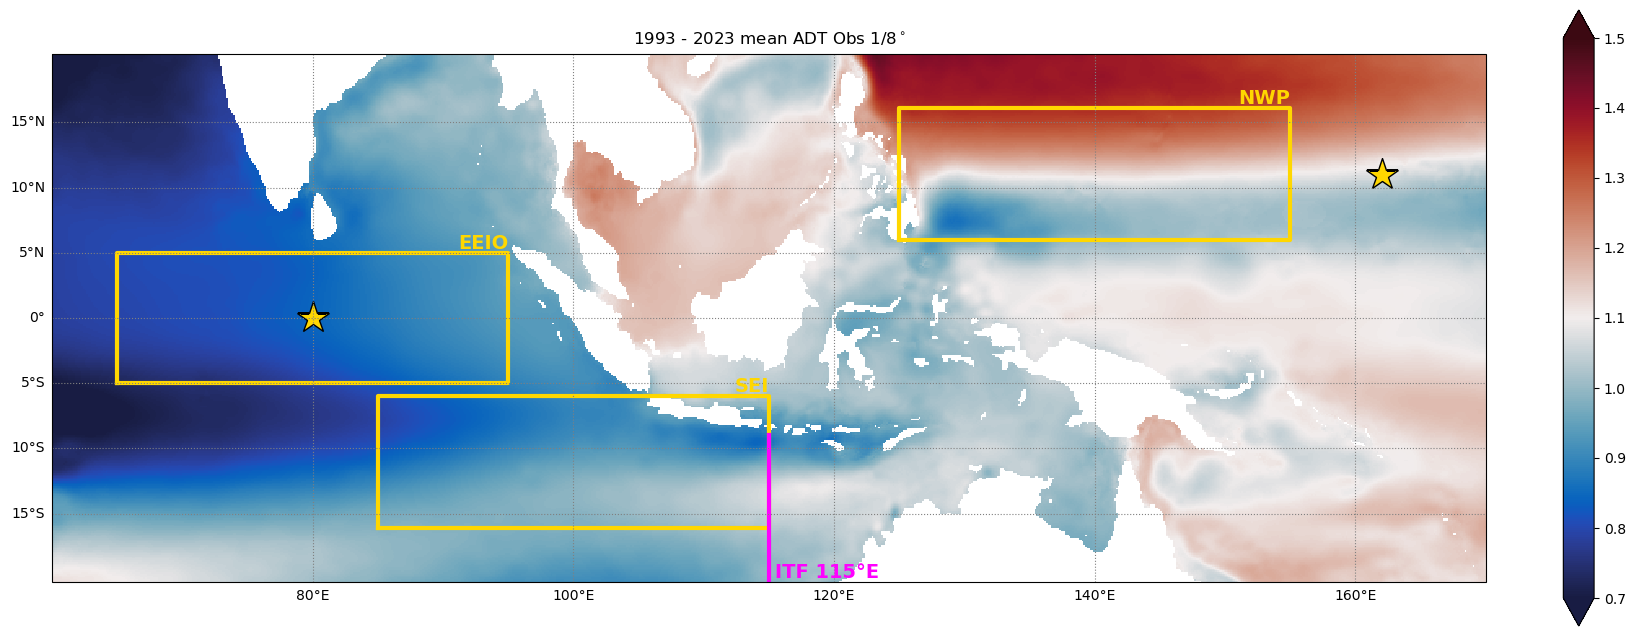

In [32]:
projection = ccrs.Mercator(central_longitude=central_longitude, min_latitude=south_latitude, max_latitude=north_latitude)

fig, axes = plt.subplots(nrows = 1, figsize = (20, 8), subplot_kw={'projection': projection}) #nrows = 3, ncols = 2, 
plt.subplots_adjust(wspace=-0.15)


# absolute dynamic topography (sla + mdt). NB: its offset differs from model zos (geoid vs arbitrary reference),
# so compare spatial patterns/gradients rather than absolute levels with the model maps above
vmin, vmax = 0.7, 1.5
p0 = ssh_obs_itf_tm[var].plot(
    ax = axes,
    vmin=vmin, vmax=vmax,
    add_colorbar=False,
    cmap = cm.cm.balance,
    transform = ccrs.PlateCarree())
axes.set_title(f"{tstart_obs.strftime('%Y')} - {tend_obs.strftime('%Y')} "+'mean ADT Obs 1/8$^\circ$')

axes.plot(lon_indian, lat_indian, '*', markersize=24, color='gold', markeredgecolor='k', transform = ccrs.PlateCarree())
axes.plot(lon_pacific, lat_pacific, '*', markersize=24, color='gold', markeredgecolor='k', transform = ccrs.PlateCarree())

for region in regions:
    if region != 'ITF':
        lon_w, lon_e = regions[region]['lon'].start, regions[region]['lon'].stop
        lat_s, lat_n = regions[region]['lat'].start, regions[region]['lat'].stop
        axes.plot([lon_w, lon_e, lon_e, lon_w, lon_w], [lat_s, lat_s, lat_n, lat_n, lat_s], color='gold', linewidth=3, transform=ccrs.PlateCarree())
        axes.text(lon_e, lat_n, region, color='gold', fontsize=14, fontweight='bold', va='bottom', ha='right', transform=ccrs.PlateCarree())

# ITF transport section (115E)
axes.plot([itf_lon, itf_lon], [itf_lat.start, itf_lat.stop], color='magenta', linewidth=3, transform=ccrs.PlateCarree())
axes.text(itf_lon + 0.5, itf_lat.start, f'ITF {itf_lon}°E', color='magenta', fontsize=14, fontweight='bold', va='bottom', ha='left', transform=ccrs.PlateCarree())

gl = axes.gridlines(color='grey', linestyle=':', draw_labels=True) #ylocs=[-45, -60, -75])
gl.top_labels = False
gl.right_labels = False

cbar = fig.colorbar(p0, ax=axes, location='right', spacing='proportional', extend='both', pad=0.05, fraction=0.025)

## Plot gradients in SSH between points

In [33]:
labels = {"obs": "CMEMS", "om3": "ACCESS-OM3", "om2": "ACCESS-OM2"}
colors = {"obs": "k", "om3": "C1", "om2": "C0"}

Text(0.5, 1.0, 'SSH difference between points/stars (Susanto and Song, 2015)')

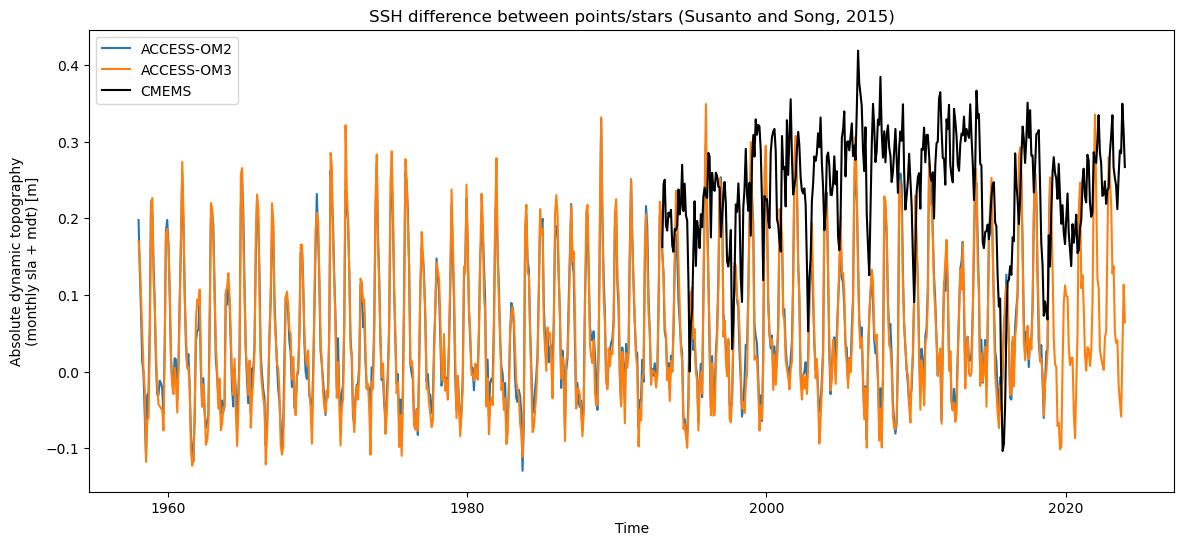

In [34]:
fig, ax = plt.subplots(figsize=(14, 6))

deta_om2.convert_calendar("proleptic_gregorian", use_cftime=True).sea_level.plot(ax=ax, x='time', label=labels['om2'], color=colors['om2'])
deta_om3.plot(ax=ax, x='time', label=labels['om3'], color=colors['om3'])
deta_obs[var].convert_calendar("proleptic_gregorian", use_cftime=True).plot(ax=ax, label=labels['obs'], color=colors['obs'])
plt.legend()
plt.title('SSH difference between points/stars (Susanto and Song, 2015)')

## SSH anomalies (SSHA) comparable to CMEMS SLA

CMEMS `sla` is SSH minus a 1993–2012 mean sea surface. It includes the seasonal cycle and global-mean sea-level rise (thermal expansion plus added mass), and has the high-frequency atmospheric response (DAC) removed.
The model `zos`/`sea_level` is the full dynamic sea level with an arbitrary offset, and (Boussinesq) contains no global thermal-expansion signal. To compare like with like, each dataset is processed identically:

1. remove the area-weighted **global mean** at each time step (removes the sea-level-rise trend from the obs, and offsets/drift from the models);
2. compute anomalies relative to a **common reference period** (`ref_period`, default 1993–2012 = the CMEMS baseline), optionally removing the monthly climatology (`deseason`), as in Shilimkar et al. (2022);
3. take **area-weighted** box means over NWP and SEI (`areacello` for OM3, `area_t` for OM2, $\cos\phi$ for the regular CMEMS grid);
4. smooth with a running mean (`smooth_months`; Shilimkar et al. use 85 months, which removes ~3.5 yr at each end of the altimetry record).

In [35]:
ref_period = slice("1993", "2012")   # CMEMS SLA reference period
deseason = True                      # remove monthly climatology (Shilimkar et al. 2022)
smooth_months = 13                   # running-mean window; Shilimkar et al. 2022 use 85
box_keys = ["NWP", "SEI"]

def anomaly(da, period=ref_period, deseason=deseason):
    # anomaly relative to `period`; optionally remove the monthly climatology of `period`
    ref = da.sel(time=period)
    if deseason:
        return (da.groupby("time.month") - ref.groupby("time.month").mean("time")).drop_vars("month")
    return da - ref.mean("time")

def global_mean(da, weights):
    # global mean area weighted
    xdim, ydim = weights.dims[-1], weights.dims[-2]
    return da.weighted(weights.fillna(0)).mean((ydim, xdim))

def box_mean(da, weights, ds_key, region_key):
    xname, yname = coord_names[ds_key]['X'], coord_names[ds_key]['Y']
    da_r = select_region(da, ds_key, region_key)
    w_r = select_region(weights, ds_key, region_key)
    return da_r.weighted(w_r.fillna(0)).mean((xname, yname))

In [36]:
# area weights for each dataset
static_om3 = xr.open_dataset(datastore.search(filename="access-om3.mom6.static.nc").df.loc[0, "path"])
area_om3 = static_om3["areacello"].load()

om2_area_search = catalog['025deg_jra55_iaf_omip2_cycle6'].search(variable="area_t")
area_om2 = om2_area_search.search(path=om2_area_search.df["path"][0]).to_dask()["area_t"].load()

# CMEMS is on a regular lat-lon grid: weight by cos(latitude), broadcast to 2D so select_region works
_obs_grid = ssh_obs["adt"].isel(time=0, drop=True)
area_obs = (np.cos(np.deg2rad(_obs_grid.latitude)) * xr.ones_like(_obs_grid.longitude)).transpose("latitude", "longitude")

In [37]:
# obs: adt and sla give identical anomalies (mdt cancels); adt is used so daily/monthly paths agree
# monthly SSH for each dataset on a common (proleptic gregorian) calendar:
# obs over their record, models over their FULL run (anomalies still use the common ref_period;
# the statistics table below uses only the overlapping period)
ssh_monthly = {
    "obs": (ssh_obs_resample if freq == "daily" else ssh_obs)["adt"].convert_calendar("proleptic_gregorian", use_cftime=True),
    "om3": ssh_om3,
    "om2": ssh_om2["sea_level"].convert_calendar("proleptic_gregorian", use_cftime=True),
}
areas = {"obs": area_obs, "om3": area_om3, "om2": area_om2}

In [38]:
%%time
# 1. remove global mean, 2. anomaly w.r.t. ref_period, 3. area-weighted box means
ssha_box = {}
for key, da in ssh_monthly.items():
    gm = global_mean(da, areas[key])
    ssha = anomaly(da - gm)
    ssha_box[key] = {
        box: box_mean(ssha, areas[key], key, box).load() for box in box_keys
    }
    print(key, "done:", str(da.time.values[0])[:7], "to", str(da.time.values[-1])[:7])

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 48.45 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 48.45 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


obs done: 1993-01 to 2023-12


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 13.95 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 13.95 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


om3 done: 1958-01 to 2023-12
om2 done: 1958-01 to 2018-12
CPU times: user 1min 51s, sys: 54.2 s, total: 2min 45s
Wall time: 2min 51s


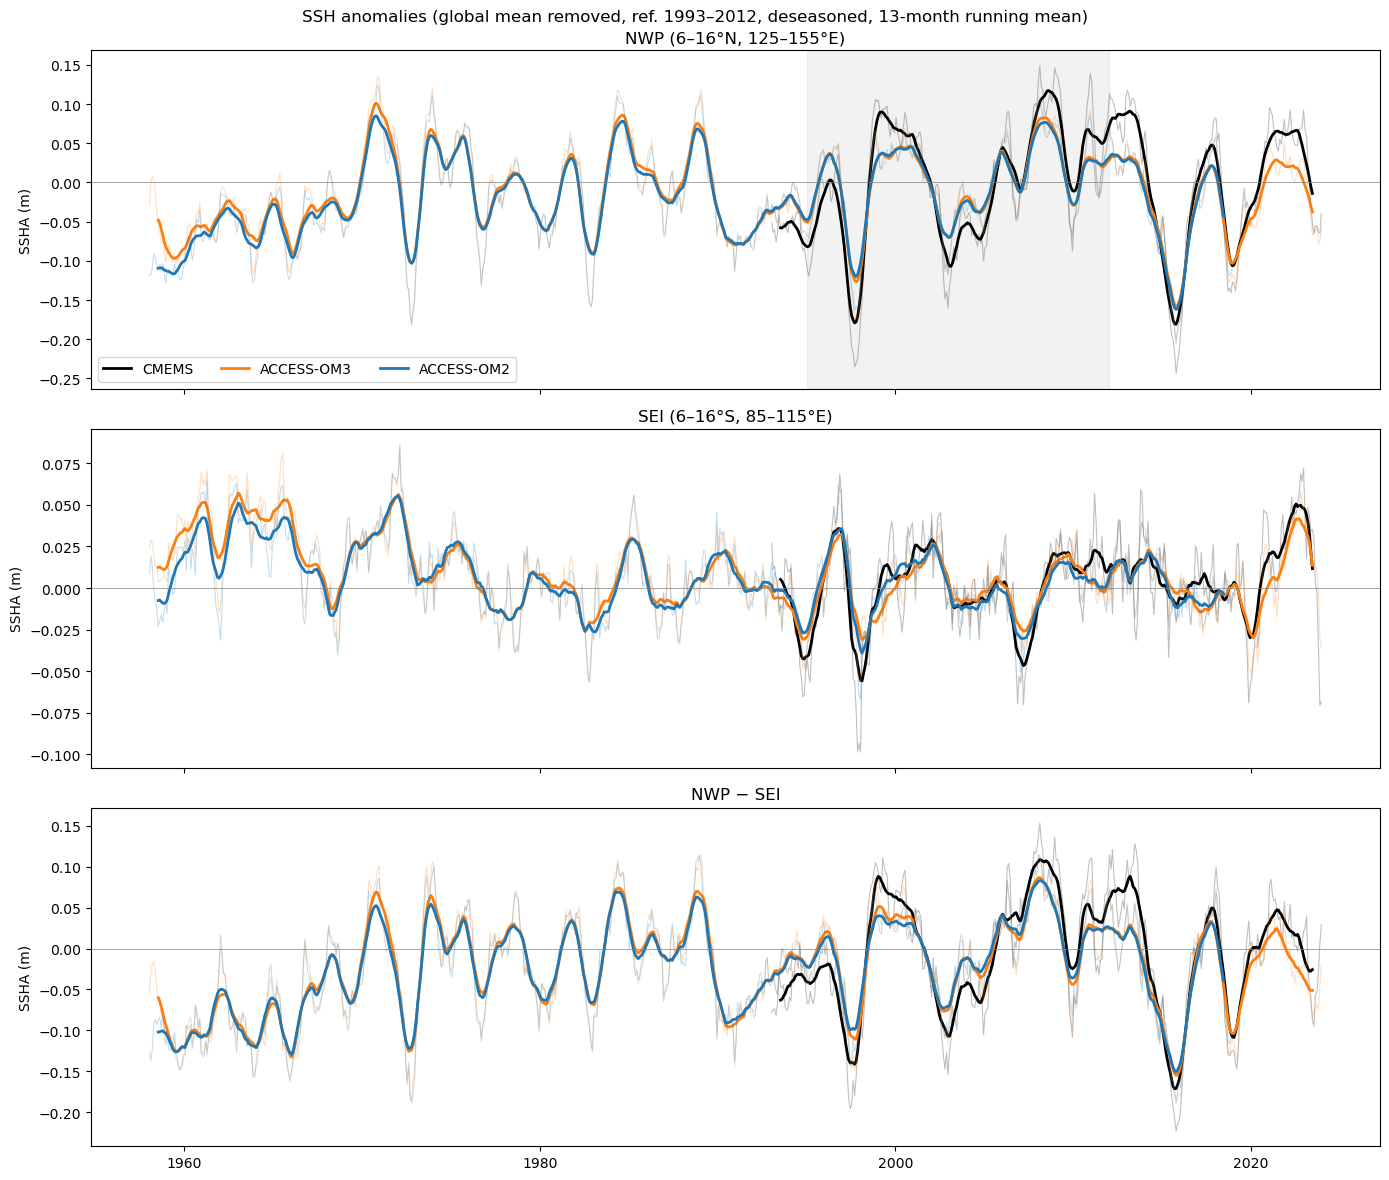

In [39]:
def cfdate(s):
    return cftime.DatetimeProlepticGregorian(*map(int, s.split("-")))

smooth_months=13
def smooth(da, n=smooth_months):
    # rolling mean based on specified number of months
    return da.rolling(time=n, center=True).mean()

fig, axes = plt.subplots(nrows=3, figsize=(14, 12), sharex=True)
for key in ssha_box:
    nwp, sei = ssha_box[key]["NWP"], ssha_box[key]["SEI"]
    for ax, da in zip(axes, [nwp, sei, nwp - sei]):
        ax.plot(da.time, da, color=colors[key], alpha=0.25, linewidth=0.8)
        ax.plot(da.time, smooth(da), color=colors[key], linewidth=2, label=labels[key])

for ax, title in zip(axes, ["NWP (6–16°N, 125–155°E)", "SEI (6–16°S, 85–115°E)", "NWP − SEI"]):
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.set_title(title)
    ax.set_ylabel("SSHA (m)")
axes[0].axvspan(cfdate("1995-01-01"), cfdate("2012-01-01"), color="grey", alpha=0.1)

axes[0].legend(ncols=3)
fig.suptitle(f"SSH anomalies (global mean removed, ref. {ref_period.start}–{ref_period.stop}, "
             f"{'deseasoned, ' if deseason else ''}{smooth_months}-month running mean)")
plt.tight_layout()

In [40]:
# statistics of monthly NWP-SEI anomalies over the common period (indexed by year-month so calendars/days don't matter)
def to_series(da):
    idx = pd.PeriodIndex([f"{y}-{m:02d}" for y, m in zip(da.time.dt.year.values, da.time.dt.month.values)], freq="M")
    return pd.Series(da.values, index=idx)

dssh = pd.DataFrame({labels[k]: to_series(v["NWP"] - v["SEI"]) for k, v in ssha_box.items()}).dropna()
print(f"common period: {dssh.index[0]} to {dssh.index[-1]}")
stats = pd.DataFrame({
    "std (m)": dssh.std(),
    "std smoothed (m)": dssh.rolling(smooth_months, center=True).mean().std(),
    "corr with CMEMS": dssh.corr()[labels["obs"]],
    "corr with CMEMS (smoothed)": dssh.rolling(smooth_months, center=True).mean().corr()[labels["obs"]],
})
stats.round(3)

common period: 1993-01 to 2018-12


,std (m),std smoothed (m),corr with CMEMS,corr with CMEMS (smoothed)
CMEMS,0.080,0.068,1.000,1.000
ACCESS-OM3,0.061,0.051,0.935,0.938
ACCESS-OM2,0.058,0.048,0.933,0.936


### Total SSH difference NWP $-$ SEI

The anomalies above show variability about each dataset's own mean. The **total** SSH difference $\Delta\eta$ (model `zos`, obs ADT = `sla` + `mdt`) also includes the mean Pacific-to-Indian height difference that drives the mean ITF (and enters the transport proxy $Q$). Constant offsets between model and obs SSH cancel in the difference, so this is a like-for-like comparison. Same area-weighted boxes as above; no global-mean removal, anomaly or deseasoning.

In [41]:
%%time
deta_box = {
    key: (box_mean(da, areas[key], key, "NWP") - box_mean(da, areas[key], key, "SEI")).load()
    for key, da in ssh_monthly.items()
}

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/client.py:3387: UserWarning: Sending large graph of size 32.62 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


CPU times: user 16.2 s, sys: 8.45 s, total: 24.7 s
Wall time: 24.4 s


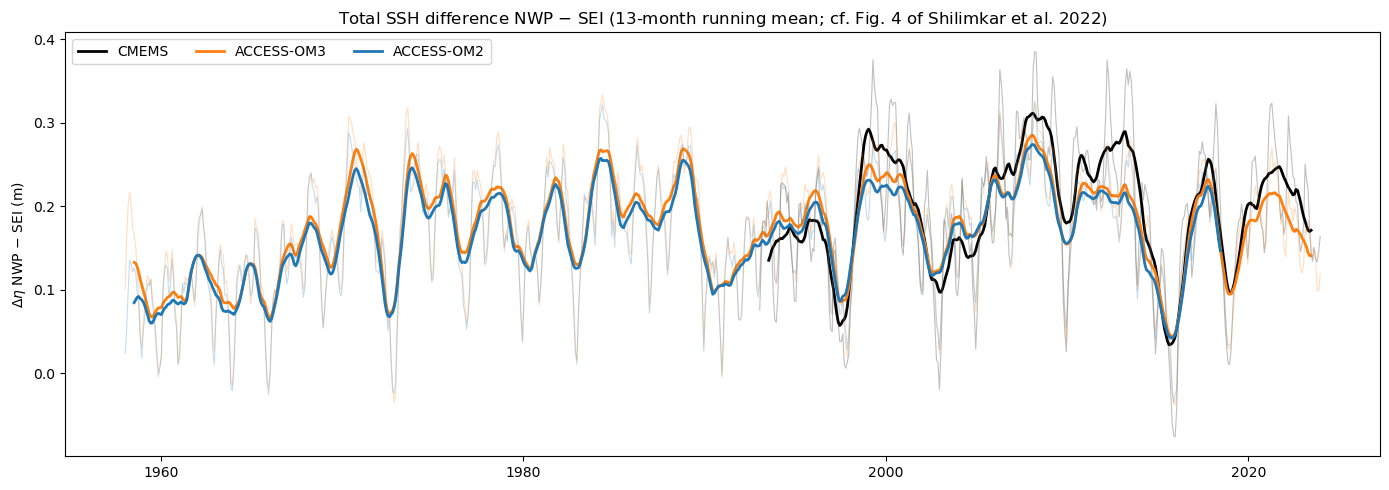

In [42]:
fig, ax = plt.subplots(figsize=(14, 5))
for key, da in deta_box.items():
    ax.plot(da.time, da, color=colors[key], alpha=0.25, linewidth=0.8)
    ax.plot(da.time, smooth(da), color=colors[key], linewidth=2, label=labels[key])
ax.set_ylabel(r"$\Delta\eta$ NWP $-$ SEI (m)")
ax.legend(ncols=3)
ax.set_title(f"Total SSH difference NWP $-$ SEI ({smooth_months}-month running mean; cf. Fig. 4 of Shilimkar et al. 2022)")
plt.tight_layout()

In [43]:
# mean and variability of the total NWP-SEI difference over the common period
deta_df = pd.DataFrame({labels[k]: to_series(v) for k, v in deta_box.items()}).dropna()
print(f"common period: {deta_df.index[0]} to {deta_df.index[-1]}")
pd.DataFrame({
    "mean Δη (m)": deta_df.mean(),
    "mean Δη − CMEMS (m)": deta_df.mean() - deta_df[labels["obs"]].mean(),
    "std Δη (m)": deta_df.std(),
}).round(3)

common period: 1993-01 to 2018-12


,mean Δη (m),mean Δη − CMEMS (m),std Δη (m)
CMEMS,0.194,0.000,0.093
ACCESS-OM3,0.186,-0.009,0.070
ACCESS-OM2,0.179,-0.016,0.066


## ITF volume transport along 115°E

Following Shilimkar et al. (2022, Fig. 1), the ITF volume transport is the full-depth (surface to bottom) zonal transport across a meridional line along **115°E** from Australia to Indonesia (**9–20°S**).

- ACCESS-OM3: vertically integrated zonal mass transport `umo_2d` (kg s$^{-1}$) on the `xq` column nearest 115°E, summed over `yh`.
- ACCESS-OM2: `tx_trans_int_z` (kg s$^{-1}$) on the `xu_ocean` column nearest 115°E, summed over `yt_ocean` (resolved transport only; GM and submesoscale parameterised transports are neglected, as in `StraitTransports.ipynb`).
- Mass transport is converted to volume transport with $\rho_0 = 1035$ kg m$^{-3}$; 1 Sv = 10$^6$ m$^3$ s$^{-1}$.
- **Sign convention: positive = westward** (Pacific → Indian), so a stronger ITF is a larger positive number, consistent with the positive regression coefficient below.

For comparison, the transport through the three main **outflow straits** (Lombok, Ombai and Timor) is computed with the same section definitions as `StraitTransports.ipynb`, and compared with the INSTANT mooring observations (Sprintall et al. 2009, 2004–2006). All water leaving the Indonesian seas through these straits must cross 115°E, so the two estimates should agree closely (115°E also includes the minor passages between them, e.g. Alas, Sape and Sumba straits).

NB: in OM3 at 115°E the coasts are at ~21.6°S (Australia) and ~8.6°S (Bali). The paper's 9–20°S line therefore omits the shallow (<260 m) shelf at 20–21.5°S and a narrow strip at 8.7–9°S; set `itf_lat = slice(-21.7, -8.5)` for a coast-to-coast section.

In [44]:
import nc_time_axis  # noqa: F401, lets matplotlib plot cftime dates with ax.plot

# itf_lon, itf_lat (the transport section) are defined with the regions at the top of the notebook
rho0 = 1035.0               # kg m-3, reference density to convert mass to volume transport

umo_2d = datastore.search(variable="umo_2d", frequency="1mon").to_dask(
    xarray_open_kwargs=dict(chunks={"time": -1}, decode_timedelta=True),
    xarray_combine_by_coords_kwargs=dict(compat="override", data_vars="minimal", coords="minimal"),
)["umo_2d"]
vmo_2d = datastore.search(variable="vmo_2d", frequency="1mon").to_dask(
    xarray_open_kwargs=dict(chunks={"time": -1}, decode_timedelta=True),
    xarray_combine_by_coords_kwargs=dict(compat="override", data_vars="minimal", coords="minimal"),
)["vmo_2d"]

om2_trans_search = catalog['025deg_jra55_iaf_omip2_cycle6'].search(variable="tx_trans_int_z", frequency="1mon")
om2_trans_search.esmcat.aggregation_control.groupby_attrs = ['frequency']  # as in StraitTransports.ipynb
tx_trans_int_z = om2_trans_search.to_dask(
    xarray_open_kwargs=dict(chunks={"time": -1}, decode_timedelta=True, use_cftime=True),
)["tx_trans_int_z"]
om2_trans_search = catalog['025deg_jra55_iaf_omip2_cycle6'].search(variable="ty_trans_int_z", frequency="1mon")
om2_trans_search.esmcat.aggregation_control.groupby_attrs = ['frequency']
ty_trans_int_z = om2_trans_search.to_dask(
    xarray_open_kwargs=dict(chunks={"time": -1}, decode_timedelta=True, use_cftime=True),
)["ty_trans_int_z"]

print("OM3 umo_2d units:", umo_2d.attrs.get("units"), "| OM2 tx_trans_int_z units:", tx_trans_int_z.attrs.get("units"))

OM3 umo_2d units: kg s-1 | OM2 tx_trans_int_z units: kg/s


In [45]:
%%time
# ITF volume transport (Sv), positive westward
umo_itf = umo_2d.sel(xq=itf_lon - 360, method="nearest")
tx_itf = tx_trans_int_z.sel(xu_ocean=itf_lon - 360, method="nearest")
print(f"OM3 section at {float(umo_itf.xq) % 360:.2f}E, OM2 section at {float(tx_itf.xu_ocean) % 360:.2f}E")

itf_transport = {
    "om3": (-umo_itf.sel(yh=itf_lat).sum("yh") / rho0 / 1e6)
           .convert_calendar("proleptic_gregorian", use_cftime=True).load(),
    "om2": (-tx_itf.sel(yt_ocean=itf_lat).sum("yt_ocean") / rho0 / 1e6)
           .convert_calendar("proleptic_gregorian", use_cftime=True).load(),
}
for k, da in itf_transport.items():
    da.attrs.update(long_name="ITF volume transport across 115E (positive westward)", units="Sv")

OM3 section at 115.00E, OM2 section at 115.00E
CPU times: user 1.72 s, sys: 1.17 s, total: 2.89 s
Wall time: 2.64 s


In [46]:
%%time
# Outflow strait sections, copied from StraitTransports.ipynb: [minlon, maxlon, minlat, maxlat] in model longitudes.
# Sections must be zonal (minlat == maxlat, uses meridional transport) or meridional (minlon == maxlon, zonal transport).
outflow_straits = {
    "om3": {  # om3straits['25km']
        "Lombok Strait": [-244.8, -243.5, -8.5, -8.5],
        "Ombai Strait":  [-235.0, -235.0, -9.21, -8.3],
        "Timor Strait":  [123-360, 123-360, -11.7, -10.7],
    },
    "om2": {  # om2straits['025deg']
        "Lombok Strait": [-244.7, -243.6, -8.22, -8.22],
        "Ombai Strait":  [-235.5, -235.5, -9.21, -8.47],
        "Timor Strait":  [123-360, 123-360, -11.7, -10.8],
    },
}
# INSTANT observations (Sprintall et al. 2009, http://dx.doi.org/10.1029/2008JC005257), Sv out of the Indonesian seas
instant_obs = {"Lombok Strait": 2.6, "Ombai Strait": 4.9, "Timor Strait": 7.5}
instant_period = slice("2004", "2006")

trans_vars = {  # zonal transport, its (x, y) dims; meridional transport, its (x, y) dims
    "om3": (umo_2d, "xq", "yh", vmo_2d, "xh", "yq"),
    "om2": (tx_trans_int_z, "xu_ocean", "yt_ocean", ty_trans_int_z, "xt_ocean", "yu_ocean"),
}

def section_transport(key, xmin, xmax, ymin, ymax):
    # full-depth transport (Sv) across a zonal or meridional section, positive out of the Indonesian seas (west/south)
    u, xu, yu, v, xv, yv = trans_vars[key]
    if xmin == xmax:
        t = u.sel({xu: xmin}, method="nearest").sel({yu: slice(ymin, ymax)}).sum(yu)
    elif ymin == ymax:
        t = v.sel({xv: slice(xmin, xmax)}).sel({yv: ymin}, method="nearest").sum(xv)
    else:
        raise ValueError("sections must be zonal or meridional")
    return (-t / rho0 / 1e6).reset_coords(drop=True).convert_calendar("proleptic_gregorian", use_cftime=True)

strait_transport = {
    key: {name: section_transport(key, *sec).load() for name, sec in secs.items()}
    for key, secs in outflow_straits.items()
}
straits_total = {key: sum(d.values()) for key, d in strait_transport.items()}

CPU times: user 4.06 s, sys: 2.84 s, total: 6.9 s
Wall time: 6.12 s


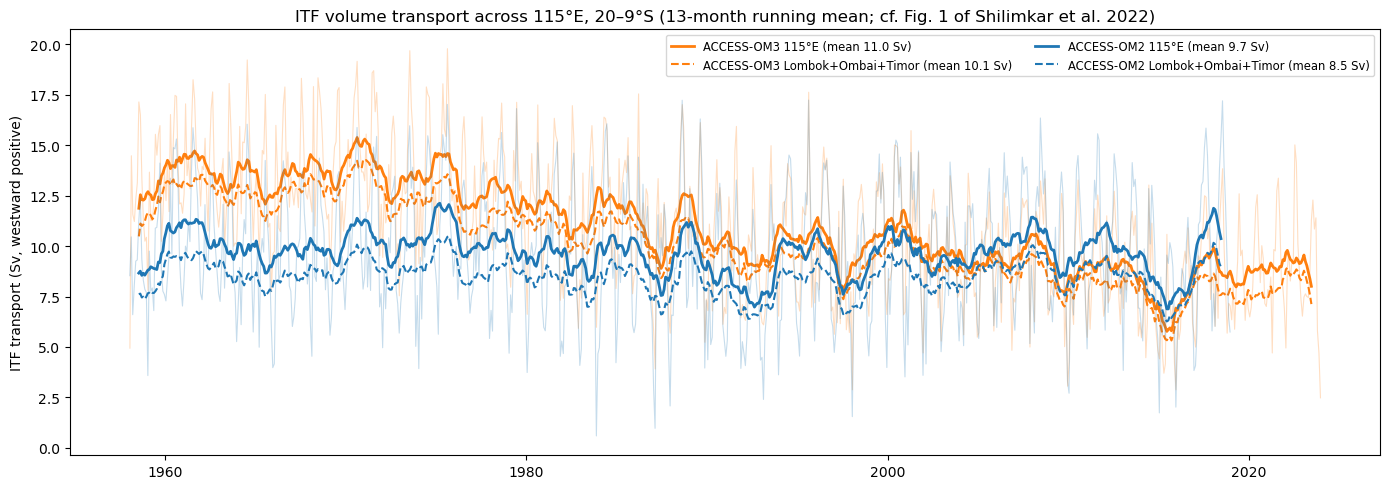

In [47]:
fig, ax = plt.subplots(figsize=(14, 5))
for key, da in itf_transport.items():
    ax.plot(da.time, da, color=colors[key], alpha=0.25, linewidth=0.8)
    ax.plot(da.time, smooth(da), color=colors[key], linewidth=2,
            label=f"{labels[key]} {itf_lon}°E (mean {float(da.mean()):.1f} Sv)")
    st = straits_total[key]
    ax.plot(st.time, smooth(st), color=colors[key], linewidth=1.5, linestyle="--",
            label=f"{labels[key]} Lombok+Ombai+Timor (mean {float(st.mean()):.1f} Sv)")
ax.set_ylabel("ITF transport (Sv, westward positive)")
ax.legend(ncols=2, fontsize='small')
ax.set_title(f"ITF volume transport across {itf_lon}°E, {-itf_lat.start}–{-itf_lat.stop}°S "
             f"({smooth_months}-month running mean; cf. Fig. 1 of Shilimkar et al. 2022)")
plt.tight_layout()

In [48]:
# mean, std and seasonal cycle of ITF transport over the common period of OM2 and OM3
itf_df = pd.DataFrame({
    **{f"{labels[k]} {itf_lon}°E": to_series(v) for k, v in itf_transport.items()},
    **{f"{labels[k]} straits": to_series(v) for k, v in straits_total.items()},
}).dropna()
print(f"common period: {itf_df.index[0]} to {itf_df.index[-1]}")
stats_itf = pd.DataFrame({
    "mean (Sv)": itf_df.mean(),
    "std (Sv)": itf_df.std(),
    "seasonal range (Sv)": itf_df.groupby(itf_df.index.month).mean().agg(lambda s: s.max() - s.min()),
})
for k in itf_transport:  # agreement between the 115E section and the sum of the outflow straits
    a, b = itf_df[f"{labels[k]} {itf_lon}°E"], itf_df[f"{labels[k]} straits"]
    stats_itf.loc[f"{labels[k]} {itf_lon}°E", "corr with straits"] = a.corr(b)
    stats_itf.loc[f"{labels[k]} {itf_lon}°E", "corr with straits (smoothed)"] = (
        a.rolling(smooth_months, center=True).mean().corr(b.rolling(smooth_months, center=True).mean()))
stats_itf.round(2)


common period: 1958-01 to 2018-12


,mean (Sv),std (Sv),seasonal range (Sv),corr with straits,corr with straits (smoothed)
ACCESS-OM3 115°E,11.15,3.28,5.69,0.94,0.99
ACCESS-OM2 115°E,9.69,3.14,7.25,0.94,0.98
ACCESS-OM3 straits,10.32,2.99,4.93,NaN,NaN
ACCESS-OM2 straits,8.49,2.40,5.56,NaN,NaN


In [49]:
# model transports averaged over the INSTANT period vs Sprintall et al. (2009); Sv out of the Indonesian seas
instant_table = {"INSTANT obs": {**instant_obs, "Lombok+Ombai+Timor": sum(instant_obs.values())}}
for key in strait_transport:
    col = {name: float(da.sel(time=instant_period).mean()) for name, da in strait_transport[key].items()}
    col["Lombok+Ombai+Timor"] = float(straits_total[key].sel(time=instant_period).mean())
    col[f"{itf_lon}°E section"] = float(itf_transport[key].sel(time=instant_period).mean())
    instant_table[labels[key]] = col
print(f"mean over {instant_period.start}–{instant_period.stop}")
pd.DataFrame(instant_table).round(2)

mean over 2004–2006


,INSTANT obs,ACCESS-OM3,ACCESS-OM2
Lombok Strait,2.6,2.19,4.31
Ombai Strait,4.9,2.49,1.42
Timor Strait,7.5,4.04,2.98
Lombok+Ombai+Timor,15.0,8.72,8.71
115°E section,NaN,9.17,9.79


## ITF transport from the SSHA difference (Wyrtki 1987)

Shilimkar et al. (2022, Fig. 4) regressed the NWP $-$ SEI SSHA difference onto the ORAS4 ITF variation:

$$\text{ITF anomaly [Sv]} = 0.185\ [\text{Sv cm}^{-1}] \times \text{SSHA difference [cm]}$$

Below:
1. this relation is applied to the NWP $-$ SEI SSHA difference of CMEMS, OM2 and OM3 (`ssha_box`, computed above) to give an SSH-based ITF anomaly estimate;
2. it is compared with the **actual** model ITF transport anomaly (same `anomaly()` processing: deseasoned, relative to `ref_period`);
3. each model's own regression coefficient is fitted, to test whether the 0.185 Sv cm$^{-1}$ ORAS4 relation holds in the models.

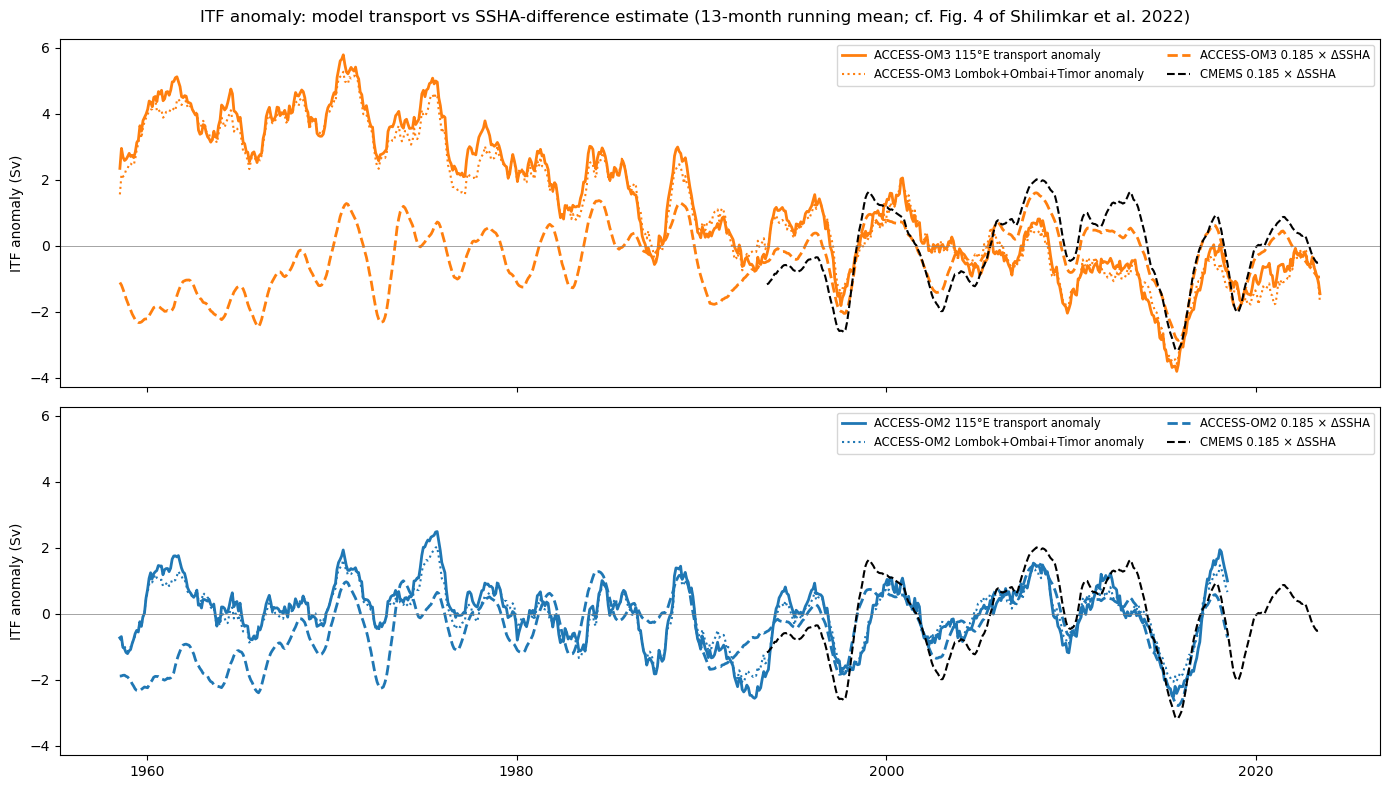

In [50]:
wyrtki_slope = 0.185  # Sv per cm, Shilimkar et al. (2022) from ORAS4

dssha_cm = {k: 100 * (v["NWP"] - v["SEI"]) for k, v in ssha_box.items()}   # NWP-SEI SSHA difference (cm) (100 is conversion from meters)
itf_proxy = {k: wyrtki_slope * d for k, d in dssha_cm.items()}             # SSH-based ITF anomaly (Sv)
itf_anom = {k: anomaly(v) for k, v in itf_transport.items()}               # model 115E transport anomaly (Sv)
straits_anom = {k: anomaly(v) for k, v in straits_total.items()}           # model Lombok+Ombai+Timor anomaly (Sv)

fig, axes = plt.subplots(nrows=len(itf_anom), figsize=(14, 4 * len(itf_anom)), sharex=True, sharey=True)
for ax, key in zip(np.atleast_1d(axes), itf_anom):
    ax.plot(itf_anom[key].time, smooth(itf_anom[key]), color=colors[key], linewidth=2,
            label=f"{labels[key]} {itf_lon}°E transport anomaly")
    ax.plot(straits_anom[key].time, smooth(straits_anom[key]), color=colors[key], linewidth=1.5, linestyle=":",
            label=f"{labels[key]} Lombok+Ombai+Timor anomaly")
    ax.plot(itf_proxy[key].time, smooth(itf_proxy[key]), color=colors[key], linewidth=2, linestyle="--",
            label=f"{labels[key]} {wyrtki_slope} × ΔSSHA")
    ax.plot(itf_proxy["obs"].time, smooth(itf_proxy["obs"]), color=colors["obs"], linewidth=1.5, linestyle="--",
            label=f"{labels['obs']} {wyrtki_slope} × ΔSSHA")
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.set_ylabel("ITF anomaly (Sv)")
    ax.legend(ncols=2, fontsize="small")
fig.suptitle(f"ITF anomaly: model transport vs SSHA-difference estimate ({smooth_months}-month running mean; "
             f"cf. Fig. 4 of Shilimkar et al. 2022)")
plt.tight_layout()